# Avaliação automática da qualidade da aorta

Comparação percentual de ImageCAS, MM-WHS, OrCaScore e **Geral**, separada por
treino, validação e teste e pelas resoluções mid/high. O Geral soma os exames
dos bancos disponíveis; não é a média simples dos percentuais dos bancos.
“Adequada” significa ausência dos alertas automáticos, não acurácia anatômica.

Para ImageCAS, a análise usa **somente os resultados canônicos**, sem fontes
históricas alternativas. Lê CSVs existentes, sem executar segmentações ou alterar
resultados. A avaliação visual e o Dice externos estão em
[Avaliação externa da aorta](../results/external_aorta_assessment.ipynb).

In [1]:
# ruff: noqa: E402
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from IPython.display import display

REPO_ROOT = next(
    path
    for path in (Path.cwd(), *Path.cwd().parents)
    if (path / "pyproject.toml").is_file()
)
sys.path.insert(0, str(REPO_ROOT / "src"))

from utils.project.runtime.paths import find_repository_root
from utils.project.analysis.aorta_automatic_quality import (
    compare_aorta_resolutions,
    default_aorta_feedback_sources,
    load_aorta_feedback_sources,
    summarize_aorta_feedback_comparison,
)
from utils.project.analysis.external_aorta_assessment import AORTA_FEEDBACK_ORDER

REPO_ROOT = find_repository_root(REPO_ROOT)
pd.set_option("display.max_columns", 30)
plt.style.use("seaborn-v0_8-whitegrid")

## 1. De onde vêm os dados?

**ImageCAS atual:** exclusivamente dos CSVs
`output/segmentation/canonical/{mid_res,high_res}/{train,val,test}/current/numeric/results_<split>.csv`.
São 30 exames de treino, 270 de validação e 700 de teste por resolução.
`current` pode ser um link para um run ou uma consolidação com origem registrada
em `source_manifest.json`. Novas execuções em `runs/canonical_metrics/` só entram
nesta comparação depois de serem promovidas a `canonical`.

**MM-WHS e OrCaScore:** por padrão, os diagnósticos já salvos nos CSVs locais
`output/segmentation/runs/<resolução>/external_ccta/<banco>/<run>/numeric/results_all.csv`:

| Banco | Resolução | Run local |
|---|---|---|
| MM-WHS | mid | `2026-09-22_18-51-28` |
| MM-WHS | high | `2026-09-22_17-47-45` |
| OrCaScore | mid | `2026-09-19_10-23-50` |
| OrCaScore | high | `2026-09-22_19-12-41` |

Esses arquivos já contêm o feedback automático; não é preciso reexecutar os
exames externos para consultá-lo. Esta análise não calcula nem apresenta Dice.
Os runs locais MM-WHS de setembro são distintos dos runs corrigidos de outubro
usados na avaliação quantitativa externa.

Se `EXTERNAL_CCTA_RESULTS_ROOT` ou `CCTA_RESULTS_ROOT` estiver definida, ela
seleciona explicitamente a árvore externa `mmwhs/` e `orcascore/`, mantendo os
runs MM-WHS de outubro. Para usar os locais nessa situação, defina
`EXTERNAL_RESULTS_ROOT = None` na configuração antes de construir `SOURCES`.
Uma fonte explícita ausente não é substituída silenciosamente por outro run.

O gráfico de cobertura distingue diagnóstico disponível, coluna não persistida,
arquivo ausente e subconjunto não aplicável. Validação existe somente no ImageCAS.
As barras percentuais usam os **registros presentes no CSV** e incluem feedback
vazio e dados insuficientes; exames sem registro são informados na cobertura.
No teste OrCaScore high há 39 registros de 40 esperados.

O Geral considera somente bancos aplicáveis com diagnósticos disponíveis.
Se algum banco aplicável estiver ausente ou sem a coluna de diagnóstico,
o agregado será **Geral parcial**, com os bancos incluídos identificados na tabela.
Na validação, o Geral corresponde apenas ao ImageCAS. Ausência de diagnóstico
não é tratada como 0% de aortas adequadas. Nenhum subconjunto ou resolução é
somado a outro. Diferenças entre N presente e esperado permanecem informadas.

In [2]:
external_root_setting = os.environ.get("EXTERNAL_CCTA_RESULTS_ROOT") or os.environ.get(
    "CCTA_RESULTS_ROOT"
)
EXTERNAL_RESULTS_ROOT = (
    Path(external_root_setting).expanduser() if external_root_setting else None
)
SOURCES = default_aorta_feedback_sources(REPO_ROOT, EXTERNAL_RESULTS_ROOT)
records, coverage = load_aorta_feedback_sources(SOURCES)
summary, comparison_coverage = summarize_aorta_feedback_comparison(records, coverage)

In [3]:
DATASETS = ["ImageCAS", "MM-WHS", "OrCaScore"]
SUBSETS = {"train": "Treino", "val": "Validação", "test": "Teste"}
FEEDBACK_COLORS = ["#22A65A", "#E6AE00", "#DA4A49", "#9CA3AF", "#64748B"]
SHORT_LABELS = [
    "Adequada",
    "Suspeita sub",
    "Suspeita sobre",
    "Insuficientes",
    "Sem feedback",
]


def cohort_rows(frame, dataset, resolution, subset):
    return frame.loc[
        frame["dataset"].eq(dataset)
        & frame["resolution"].eq(resolution)
        & frame["subset"].eq(subset)
    ]


def show_source_coverage(selected_coverage):
    statuses = [
        "Disponível",
        "Diagnóstico não persistido",
        "Arquivo ausente",
        "Não se aplica",
        "Coorte vazia",
    ]
    colors = ["#D8F0E0", "#FFF0BD", "#F9D3D3", "#E5E7EB", "#DBEAFE"]
    fig, ax = plt.subplots(figsize=(15, 3.5), layout="constrained")
    for y, dataset in enumerate(DATASETS):
        for x, (resolution, subset) in enumerate(
            (resolution, subset) for resolution in ("mid", "high") for subset in SUBSETS
        ):
            row = cohort_rows(selected_coverage, dataset, resolution, subset)
            status = row["status"].iloc[0] if not row.empty else "Arquivo ausente"
            color = colors[statuses.index(status)]
            ax.add_patch(
                plt.Rectangle(
                    (x - 0.48, y - 0.45), 0.96, 0.9, facecolor=color, edgecolor="white"
                )
            )
            label = status
            if not row.empty and pd.notna(row["exam_count"].iloc[0]):
                count = int(row["exam_count"].iloc[0])
                expected = row["expected_count"].iloc[0]
                label += f"\nN={count}" + (
                    f"/{int(expected)}" if pd.notna(expected) else ""
                )
            ax.text(
                x,
                y,
                label.replace(
                    "Diagnóstico não persistido", "Diagnóstico\nnão persistido"
                ),
                ha="center",
                va="center",
                fontsize=9,
            )
    ax.set(
        xticks=range(6),
        xticklabels=[
            f"{r.upper()} / {name}"
            for r in ("mid", "high")
            for name in SUBSETS.values()
        ],
        yticks=range(3),
        yticklabels=DATASETS,
        xlim=(-0.5, 5.5),
        ylim=(2.5, -0.5),
        title="Cobertura das fontes atuais por dataset e subconjunto",
    )
    ax.grid(False)
    plt.show()


def show_dataset_comparison(
    selected_summary, selected_coverage, title, resolutions=("mid", "high")
):
    fig, axes = plt.subplots(
        len(resolutions),
        3,
        figsize=(18, 4 * len(resolutions) + 1),
        squeeze=False,
        layout="constrained",
    )
    for row_index, resolution in enumerate(resolutions):
        for column_index, (subset, subset_label) in enumerate(SUBSETS.items()):
            ax = axes[row_index, column_index]
            labels = []
            for y, dataset in enumerate([*DATASETS, "Geral"]):
                group = cohort_rows(selected_summary, dataset, resolution, subset)
                source = cohort_rows(selected_coverage, dataset, resolution, subset)
                count = source["exam_count"].iloc[0] if not source.empty else pd.NA
                label = dataset
                if (
                    dataset == "Geral"
                    and not source.empty
                    and source["status"].iloc[0] == "Parcial"
                ):
                    label = "Geral parcial"
                labels.append(label + (f" (N={int(count)})" if pd.notna(count) else ""))
                if group.empty:
                    status = (
                        source["status"].iloc[0]
                        if not source.empty
                        else "Arquivo ausente"
                    )
                    ax.text(
                        50,
                        y,
                        status,
                        ha="center",
                        va="center",
                        color="#666666",
                        fontsize=9,
                    )
                    continue
                values = group.set_index("status")["percent"].reindex(
                    AORTA_FEEDBACK_ORDER, fill_value=0
                )
                left = 0
                for percent, color in zip(values, FEEDBACK_COLORS, strict=True):
                    ax.barh(
                        y,
                        percent,
                        left=left,
                        color=color,
                        height=0.55,
                        edgecolor="#333333" if dataset == "Geral" else "none",
                        linewidth=0.8,
                    )
                    if percent >= 8:
                        ax.text(
                            left + percent / 2,
                            y,
                            f"{percent:.1f}%".replace(".", ","),
                            ha="center",
                            va="center",
                            fontsize=9,
                        )
                    left += percent
            ax.set(
                yticks=range(4),
                yticklabels=labels,
                ylim=(3.65, -0.65),
                xlim=(0, 100),
                xlabel="Exames presentes no CSV (%)",
                title=f"{subset_label} — {resolution.upper()}",
            )
            ax.grid(axis="y", visible=False)
    fig.suptitle(title, fontsize=15)
    fig.legend(
        handles=[
            Patch(facecolor=color, label=status)
            for status, color in zip(AORTA_FEEDBACK_ORDER, FEEDBACK_COLORS, strict=True)
        ],
        loc="outside lower center",
        ncol=3,
        frameon=False,
    )
    plt.show()


def show_paired_transitions(paired_records, paired_coverage):
    available = (
        paired_records.loc[
            paired_records["diagnostic_mid_available"].eq(True)
            & paired_records["diagnostic_high_available"].eq(True)
        ]
        if not paired_records.empty
        else paired_records
    )
    if available.empty:
        fig, ax = plt.subplots(figsize=(9, 2.5), layout="constrained")
        ax.text(
            0.5,
            0.5,
            "Sem diagnósticos mid/high pareados nas fontes disponíveis",
            ha="center",
            va="center",
            transform=ax.transAxes,
        )
        ax.set_axis_off()
        plt.show()
        return
    groups = list(available.groupby(["dataset", "subset"], sort=False))
    columns = min(3, len(groups))
    rows = (len(groups) + columns - 1) // columns
    fig, axes = plt.subplots(
        rows,
        columns,
        figsize=(6 * columns, 5 * rows),
        squeeze=False,
        layout="constrained",
    )
    for ax, ((dataset, subset), group) in zip(
        axes.ravel()[: len(groups)], groups, strict=True
    ):
        counts = pd.crosstab(group["feedback_mid"], group["feedback_high"]).reindex(
            index=AORTA_FEEDBACK_ORDER, columns=AORTA_FEEDBACK_ORDER, fill_value=0
        )
        percentages = counts / len(group) * 100
        image = ax.imshow(percentages, vmin=0, vmax=100, cmap="Blues")
        for y in range(len(counts)):
            for x in range(len(counts.columns)):
                value = percentages.iloc[y, x]
                ax.text(
                    x,
                    y,
                    f"{value:.1f}%" if value else "—",
                    ha="center",
                    va="center",
                    color="white" if value > 50 else "#333333",
                    fontsize=8,
                )
        info = paired_coverage.loc[
            paired_coverage["dataset"].eq(dataset)
            & paired_coverage["subset"].eq(subset)
        ].iloc[0]
        ax.set(
            xticks=range(5),
            xticklabels=SHORT_LABELS,
            yticks=range(5),
            yticklabels=SHORT_LABELS,
            xlabel="Classificação HIGH",
            ylabel="Classificação MID",
            title=f"{dataset} / {SUBSETS[subset]}\nN={len(group)} pares; exclusivos mid/high: {len(info['mid_only_ids'])}/{len(info['high_only_ids'])}",
        )
        ax.tick_params(axis="x", labelrotation=65)
        ax.grid(False)
    for ax in axes.ravel()[len(groups) :]:
        ax.set_axis_off()
    fig.colorbar(
        image,
        ax=axes.ravel()[: len(groups)].tolist(),
        label="Exames pareados (%)",
        shrink=0.7,
    )
    plt.show()


def show_absolute_relative_table(selected_summary, selected_coverage):
    rows = []
    for resolution in ("mid", "high"):
        for subset, subset_label in SUBSETS.items():
            for dataset in [*DATASETS, "Geral"]:
                group = cohort_rows(selected_summary, dataset, resolution, subset)
                source = cohort_rows(selected_coverage, dataset, resolution, subset)
                source = source.iloc[0]
                label = (
                    "Geral parcial"
                    if dataset == "Geral" and source["status"] == "Parcial"
                    else dataset
                )
                status = source["status"]
                if dataset == "Geral" and source.get("included_datasets", ""):
                    status += "; inclui: " + source["included_datasets"]
                row = {
                    "Resolução": resolution.upper(),
                    "Subconjunto": subset_label,
                    "Banco": label,
                    "N": source["exam_count"],
                    "N esperado": source["expected_count"],
                    "Cobertura": status,
                }
                for category in AORTA_FEEDBACK_ORDER:
                    value = group.loc[group["status"].eq(category)]
                    row[category] = (
                        f"{int(value['count'].iloc[0])} ({value['percent'].iloc[0]:.2f}%)".replace(
                            ".", ","
                        )
                        if not value.empty
                        else "—"
                    )
                rows.append(row)
    table = pd.DataFrame(rows).set_index(["Resolução", "Subconjunto", "Banco"])

    for column in ("N", "N esperado"):
        table[column] = table[column].map(
            lambda value: str(int(value)) if pd.notna(value) else "—"
        )
    with pd.option_context("display.max_rows", None, "display.max_columns", None):
        display(table)

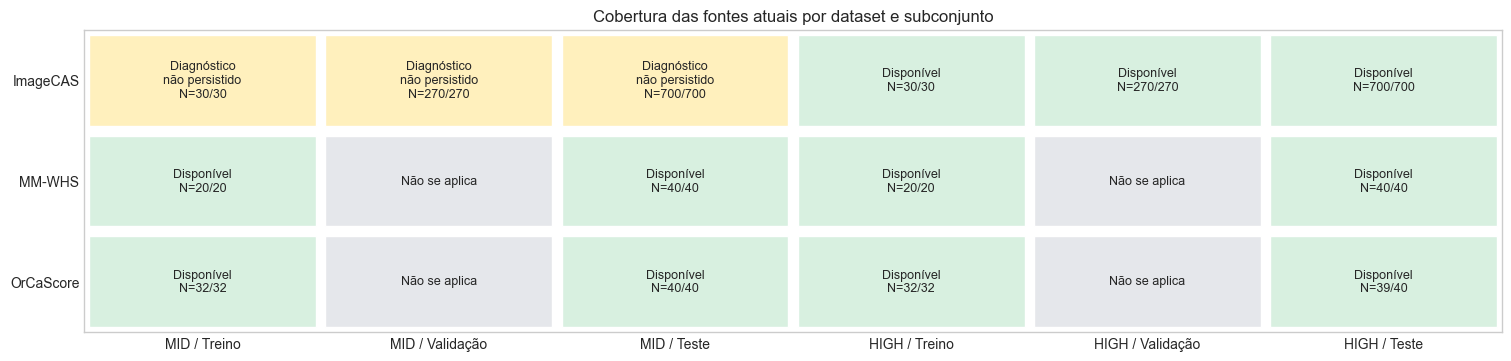

In [4]:
show_source_coverage(coverage.loc[coverage["reference"].eq("Atual")])

## 2. Critérios automáticos da aorta

Os diagnósticos persistidos são produzidos por `classify_aorta_segmentation_feedback`, com os critérios de `LEVEL_SET.quality_feedback` dos respectivos runs. As referências selecionadas usam as regras abaixo. A classificação segue esta ordem:

1. **Dados insuficientes:** alguma das três medições — preenchimento dos círculos Q25, razão área/círculo P90 ou fração volumétrica da aorta — está ausente ou não é finita.
2. **Suspeita de sobresegmentação:** razão área/círculo P90 **> 3,0**; ou fração volumétrica **> 0,019** junto com razão área/círculo P90 **> 2,8**.
3. **Suspeita de subsegmentação:** pelo menos **2 dos 3 sinais**: preenchimento dos círculos Q25 **< 0,80**; razão área/círculo P90 **< 1,30**; fração volumétrica **< 0,008**.
4. **Adequada:** nenhuma das condições anteriores foi atendida.

Os limiares são estritos (maior/menor, sem incluir igualdade). “Adequada” significa ausência desses alertas, não confirmação por ground truth. A fração volumétrica depende do volume processado e do campo de visão; os alertas não substituem o Dice nem a inspeção visual.

**Sem feedback** é um registro com a coluna de diagnóstico presente, mas valor vazio.
**Diagnóstico não persistido** significa que a coluna inteira está ausente; não é uma classe do algoritmo.
**Arquivo ausente** e **Não se aplica** são estados da cobertura, não resultados de classificação.
Se um CSV canônico não tiver a coluna de diagnóstico, essa coorte ficará indisponível nesta análise até a promoção de uma referência com os diagnósticos persistidos.

## 3. Resultados relativos dos bancos e Geral

Cada painel compara ImageCAS, MM-WHS, OrCaScore e Geral no mesmo subconjunto e
resolução. As barras mostram as cinco categorias em uma escala comum de 0 a 100%,
com N ao lado do nome. O Geral, destacado por contorno, é ponderado pelo número
de exames: **soma das contagens da categoria / soma dos registros incluídos**.
O maior banco contribui com mais exames para o Geral, mas cada barra individual
tem o próprio denominador. Ausências aparecem com indicação textual.
“Geral parcial” considera somente os bancos identificados na tabela abaixo.

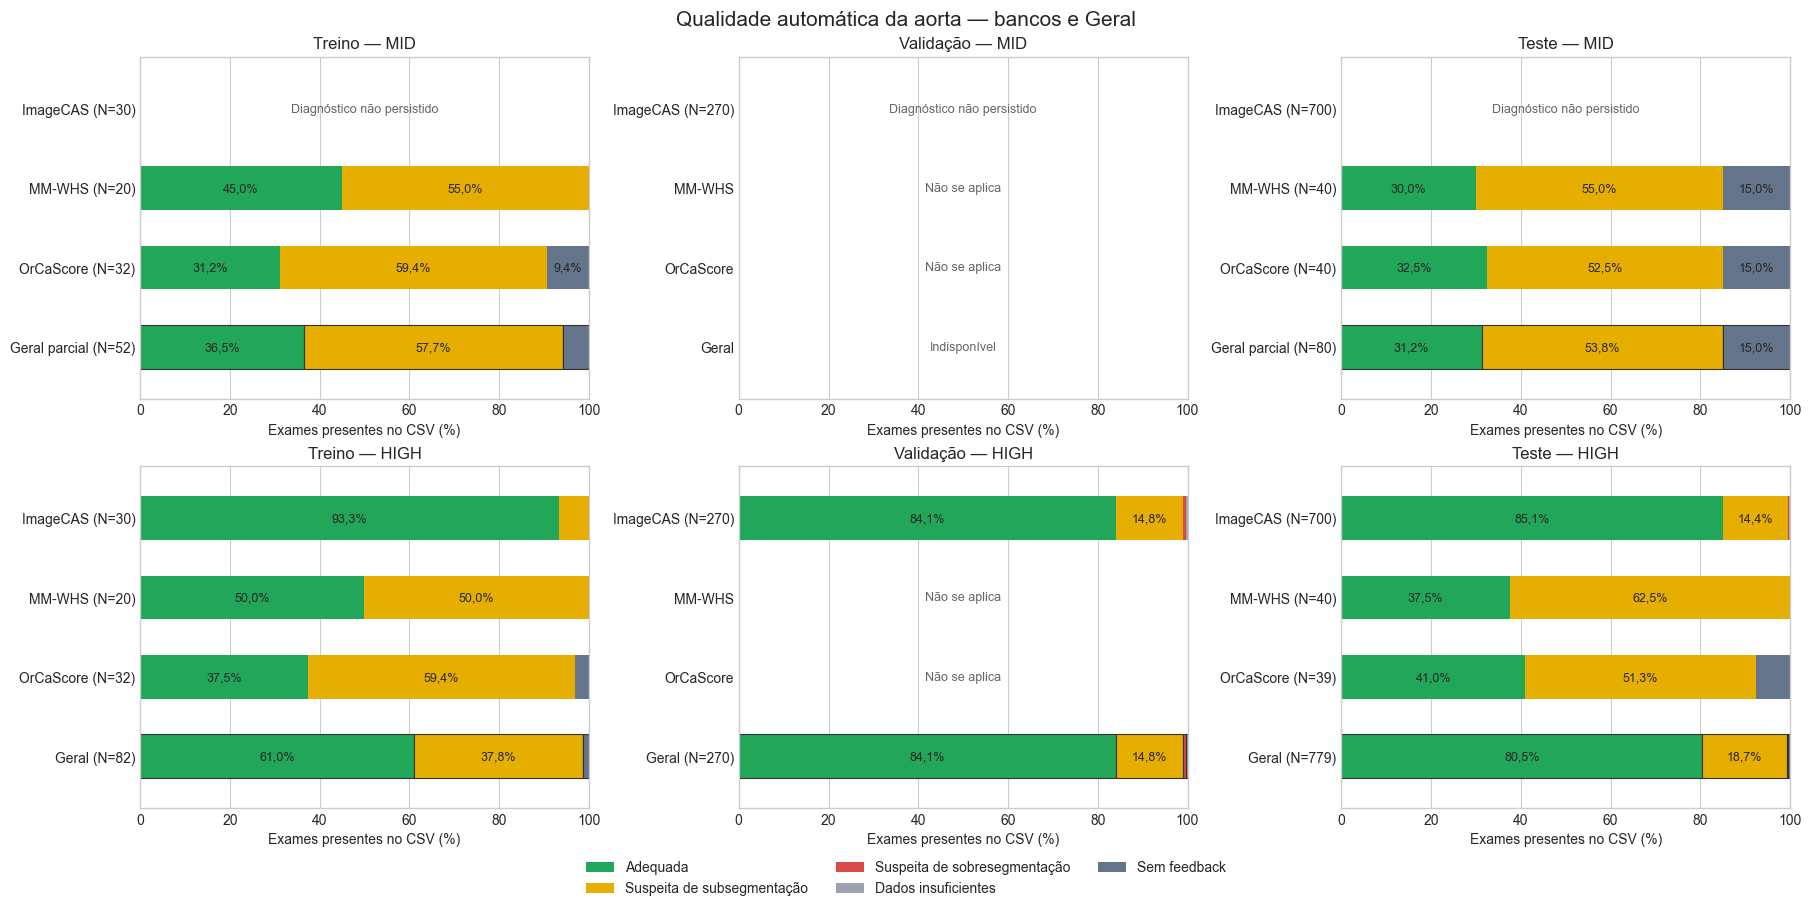

In [5]:
current_summary = summary.loc[summary["reference"].eq("Atual")]
current_coverage = comparison_coverage.loc[comparison_coverage["reference"].eq("Atual")]
show_dataset_comparison(
    current_summary, current_coverage, "Qualidade automática da aorta — bancos e Geral"
)

## 4. Resultados absolutos e relativos

Cada categoria é apresentada como **n (percentual)**, usando o mesmo denominador
do gráfico. N por banco conta os registros lidos; N do Geral conta somente os
registros que contribuíram para o agregado. Uma coluna de diagnóstico ausente
aparece como “—”, não como zero. “Sem feedback” é uma categoria registrada e
permanece no denominador. N esperado permite identificar registros ausentes.

O Geral fica indisponível se nenhum banco contribuir. Na validação, os bancos
externos são “Não se aplica” e não tornam o agregado parcial.

In [6]:
show_absolute_relative_table(current_summary, current_coverage)

N N esperado  \
Resolução Subconjunto Banco                           
MID       Treino      ImageCAS        30         30   
                      MM-WHS          20         20   
                      OrCaScore       32         32   
                      Geral parcial   52         82   
          Validação   ImageCAS       270        270   
                      MM-WHS           —          —   
                      OrCaScore        —          —   
                      Geral            —        270   
          Teste       ImageCAS       700        700   
                      MM-WHS          40         40   
                      OrCaScore       40         40   
                      Geral parcial   80        780   
HIGH      Treino      ImageCAS        30         30   
                      MM-WHS          20         20   
                      OrCaScore       32         32   
                      Geral           82         82   
          Validação   ImageCAS       270        270   
                      MM-WHS           —          —   
                      OrCaScore        —          —   
                      Geral          270        270   
          Teste       ImageCAS       700        700   
                      MM-WHS          40         40   
                      OrCaScore       39         40   
                      Geral          779        780   

                                                                           Cobertura  \
Resolução Subconjunto Banco                                                            
MID       Treino      ImageCAS                            Diagnóstico não persistido   
                      MM-WHS                                              Disponível   
                      OrCaScore                                           Disponível   
                      Geral parcial               Parcial; inclui: MM-WHS, OrCaScore   
          Validação   ImageCAS                            Diagnóstico não persistido   
                      MM-WHS                                           Não se aplica   
                      OrCaScore                                        Não se aplica   
                      Geral                                             Indisponível   
          Teste       ImageCAS                            Diagnóstico não persistido   
                      MM-WHS                                              Disponível   
                      OrCaScore                                           Disponível   
                      Geral parcial               Parcial; inclui: MM-WHS, OrCaScore   
HIGH      Treino      ImageCAS                                            Disponível   
                      MM-WHS                                              Disponível   
                      OrCaScore                                           Disponível   
                      Geral          Disponível; inclui: ImageCAS, MM-WHS, OrCaScore   
          Validação   ImageCAS                                            Disponível   
                      MM-WHS                                           Não se aplica   
                      OrCaScore                                        Não se aplica   
                      Geral                             Disponível; inclui: ImageCAS   
          Teste       ImageCAS                                            Disponível   
                      MM-WHS                                              Disponível   
                      OrCaScore                                           Disponível   
                      Geral          Disponível; inclui: ImageCAS, MM-WHS, OrCaScore   

                                         Adequada Suspeita de subsegmentação  \
Resolução Subconjunto Banco                                                    
MID       Treino      ImageCAS                  —                          —   
                      MM-WHS           9 (45,00%)                11 (55,00%)   

## 5. Mudanças de classificação entre mid e high

Os mapas de calor mostram a classificação mid nas linhas e high nas colunas.
Cada célula é o percentual do **total de exames pareados do painel**, de forma
que as células somam 100%. O pareamento usa os mesmos IDs, separados por dataset
e subconjunto; o título informa o N e quantos IDs são exclusivos de cada resolução.
Somente exames com a coluna de diagnóstico presente nas duas resoluções entram.
Feedback vazio continua sendo “Sem feedback”.

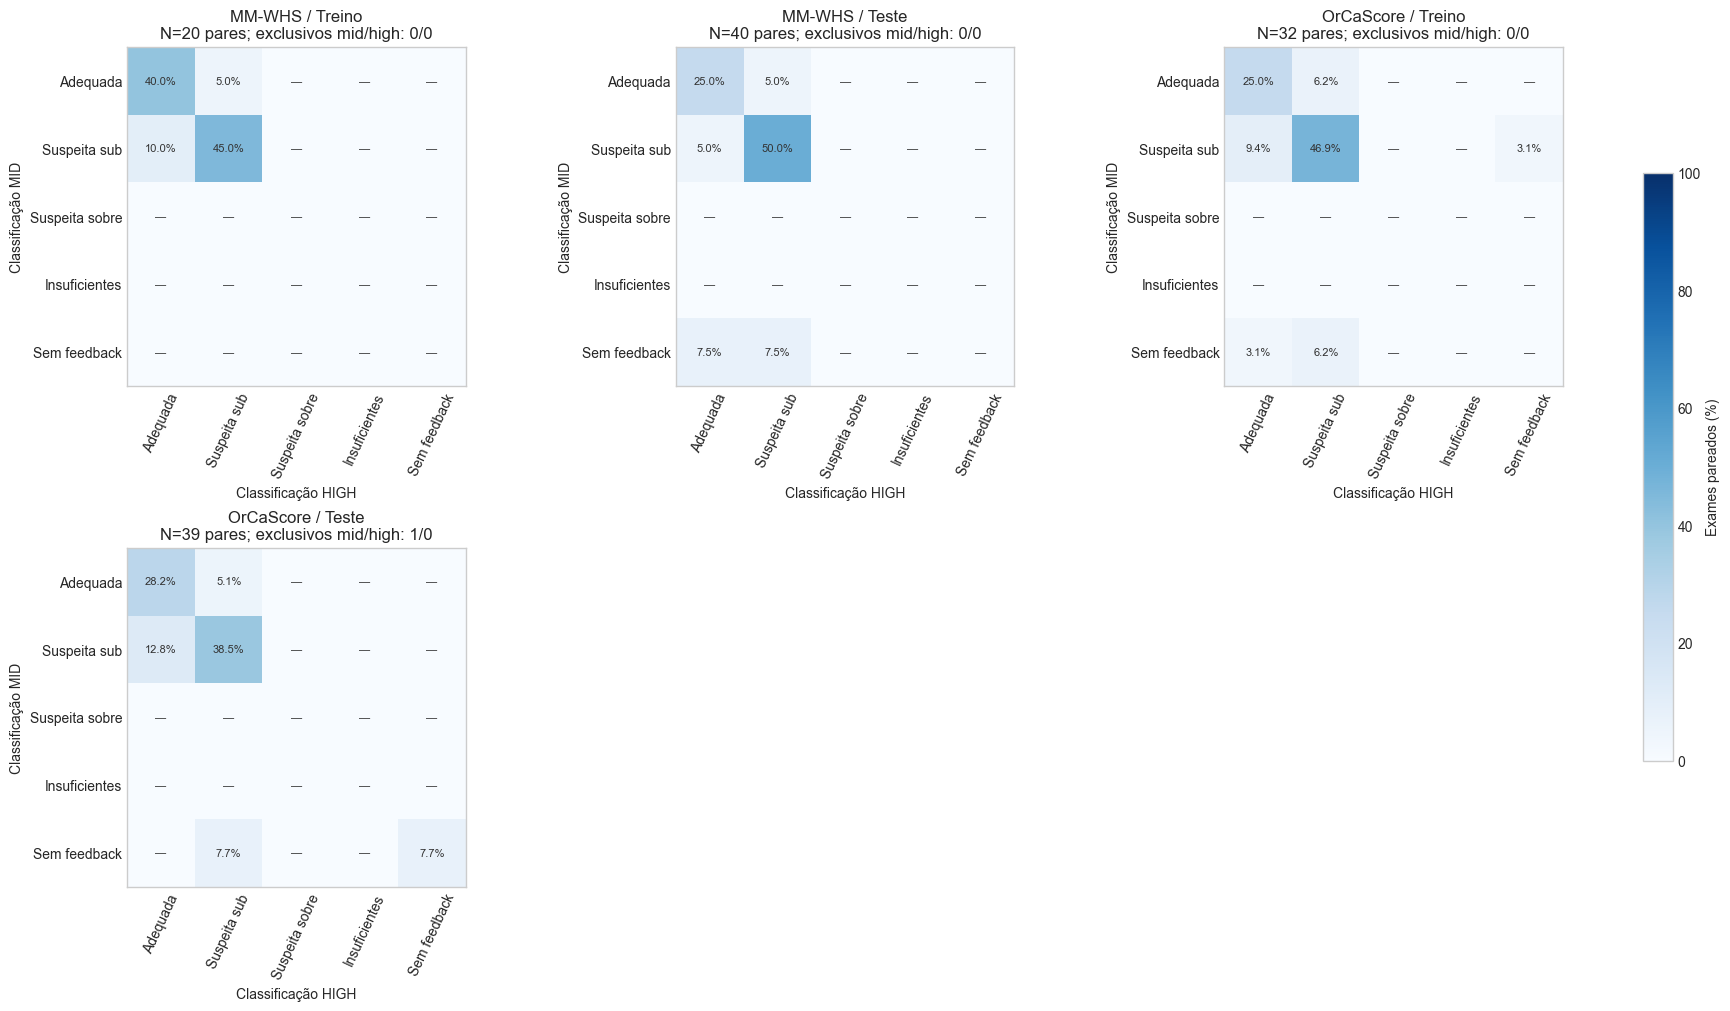

In [7]:
paired, pairing_coverage = compare_aorta_resolutions(
    records.loc[records["reference"].eq("Atual")]
)
show_paired_transitions(paired, pairing_coverage)